# Week 2 - Baseline: rolling-window Markowitz

**Goal.** Implement the reference strategy every model will be compared with, and get its first results on the
**validation period (2010-2016)**. The test period (2017-2026) is not touched.

**Protocol (same for every model).** Each Friday *t*:
1. estimate $\hat\mu_t$ and $\hat\Sigma_t$ with data known at the close of *t* only;
2. choose weights with the same Markowitz optimizer (max Sharpe in excess of $r_f$, long-only, cap $w_{max}$);
3. hold them during week *t+1*, pay 10 bps per unit of turnover.

The code is in `src/` (`backtest.py`, `baseline.py`, `metrics.py`); this notebook only runs it.

In [1]:
import sys
sys.path.insert(0, "..")          # run from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config as C
from src.backtest import walk_forward, markowitz_strategy, walk_forward_forecasts
from src.baseline import rolling_estimate, expanding_mean_estimate, equal_weight, spy_buy_and_hold
from src.metrics import portfolio_metrics, forecast_metrics

pd.set_option("display.precision", 3)
df = pd.read_csv(C.PROCESSED_DIR / "weekly_dataset.csv", index_col=0, parse_dates=True)
print(df.shape)
df["split"].value_counts()

(1142, 23)


split
test          516
validation    366
pool          260
Name: count, dtype: int64

## 1. One run of the baseline

52-week window, cap 40 %. `walk_forward` returns one row per week: the weights decided at *t*,
the gross and net return of week *t+1*, the turnover and the risk-free rate.

In [2]:
baseline = markowitz_strategy(rolling_estimate(window=52), w_max=0.40)
res = walk_forward(df, baseline, C.VALID_START, C.VALID_END, cost_bps=10)
res.head()

,gross,net,turnover,rf,w_SPY,w_EEM,w_IEF,w_LQD,w_GLD,w_VNQ
week,,,,,,,,,,
2010-01-01,0.028,0.027,1.000,9.615e-06,0.000e+00,0.272,3.063e-17,0.393,0.335,0.000e+00
2010-01-08,-0.010,-0.011,0.198,7.692e-06,5.754e-17,0.313,1.435e-17,0.287,0.400,0.000e+00
2010-01-15,-0.029,-0.029,0.052,1.058e-05,3.582e-17,0.308,0.000e+00,0.315,0.376,0.000e+00
2010-01-22,-0.013,-0.013,0.343,8.654e-06,8.043e-18,0.294,9.693e-02,0.400,0.209,5.149e-17
2010-01-29,-0.012,-0.012,0.085,1.346e-05,0.000e+00,0.292,1.365e-01,0.400,0.171,0.000e+00


In [3]:
pd.Series(portfolio_metrics(res))

ann_return      0.046
ann_vol         0.068
sharpe          0.691
max_drawdown   -0.100
avg_turnover    0.133
dtype: float64

## 2. Grid search on the validation period

We tune the **window** (26, 52, 104 weeks), the **cap** $w_{max}$ (30 %, 40 %) and the **mode**
(max-Sharpe, which uses $\hat\mu$ and $\hat\Sigma$, or minimum-variance, which uses $\hat\Sigma$ only):
12 configurations, ranked by the validation Sharpe ratio net of costs. The best one is the baseline every model must beat.

Why not `GridSearchCV`? Its default K-fold mixes past and future weeks. Here the split is chronological and fixed
(like `PredefinedSplit`): every configuration is evaluated on the same validation weeks, walking forward.

In [4]:
grid = []
for window in [26, 52, 104]:
    for w_max in [0.30, 0.40]:
        for min_var in [False, True]:
            strat = markowitz_strategy(rolling_estimate(window), w_max, min_variance=min_var)
            res_g = walk_forward(df, strat, C.VALID_START, C.VALID_END)
            grid.append({"window": window, "w_max": w_max,
                         "mode": "min-variance" if min_var else "max-Sharpe",
                         **portfolio_metrics(res_g)})
grid = pd.DataFrame(grid).sort_values("sharpe", ascending=False)
grid

,window,w_max,mode,ann_return,ann_vol,sharpe,max_drawdown,avg_turnover
11,104,0.4,min-variance,0.072,0.046,1.517,-0.053,0.014
9,104,0.3,min-variance,0.075,0.053,1.389,-0.056,0.011
7,52,0.4,min-variance,0.064,0.047,1.305,-0.063,0.023
10,104,0.4,max-Sharpe,0.073,0.055,1.286,-0.055,0.060
5,52,0.3,min-variance,0.070,0.053,1.276,-0.068,0.018
8,104,0.3,max-Sharpe,0.077,0.061,1.231,-0.059,0.046
3,26,0.4,min-variance,0.059,0.050,1.169,-0.072,0.044
1,26,0.3,min-variance,0.065,0.055,1.156,-0.073,0.034
4,52,0.3,max-Sharpe,0.059,0.069,0.849,-0.088,0.104
0,26,0.3,max-Sharpe,0.051,0.073,0.702,-0.122,0.146


In [5]:
best = grid.iloc[0]
BEST_WINDOW, BEST_CAP = int(best["window"]), float(best["w_max"])
BEST_MINVAR = best["mode"] == "min-variance"
print(f"Selected baseline: window = {BEST_WINDOW} weeks, cap = {BEST_CAP:.0%}, mode = {best['mode']}")

Selected baseline: window = 104 weeks, cap = 40%, mode = min-variance


## 3. Baseline vs benchmarks (validation, net of costs)

In [6]:
BEST_NAME = f"Baseline ({best['mode']}, {BEST_WINDOW}w, cap {BEST_CAP:.0%})"
strategies = {
    BEST_NAME: markowitz_strategy(rolling_estimate(BEST_WINDOW), BEST_CAP, min_variance=BEST_MINVAR),
    "Best max-Sharpe (104w, cap 40%)": markowitz_strategy(rolling_estimate(104), 0.40),
    "Spec default (max-Sharpe, 52w, cap 40%)": markowitz_strategy(rolling_estimate(52), 0.40),
    "1/N": equal_weight,
    "SPY buy-and-hold": spy_buy_and_hold,
}
results = {name: walk_forward(df, f, C.VALID_START, C.VALID_END) for name, f in strategies.items()}
summary = pd.DataFrame({name: portfolio_metrics(r) for name, r in results.items()}).T
summary

,ann_return,ann_vol,sharpe,max_drawdown,avg_turnover
"Baseline (min-variance, 104w, cap 40%)",0.072,0.046,1.517,-0.053,0.014
"Best max-Sharpe (104w, cap 40%)",0.073,0.055,1.286,-0.055,0.060
"Spec default (max-Sharpe, 52w, cap 40%)",0.046,0.068,0.691,-0.100,0.133
1/N,0.068,0.092,0.754,-0.107,0.012
SPY buy-and-hold,0.129,0.144,0.910,-0.170,0.000


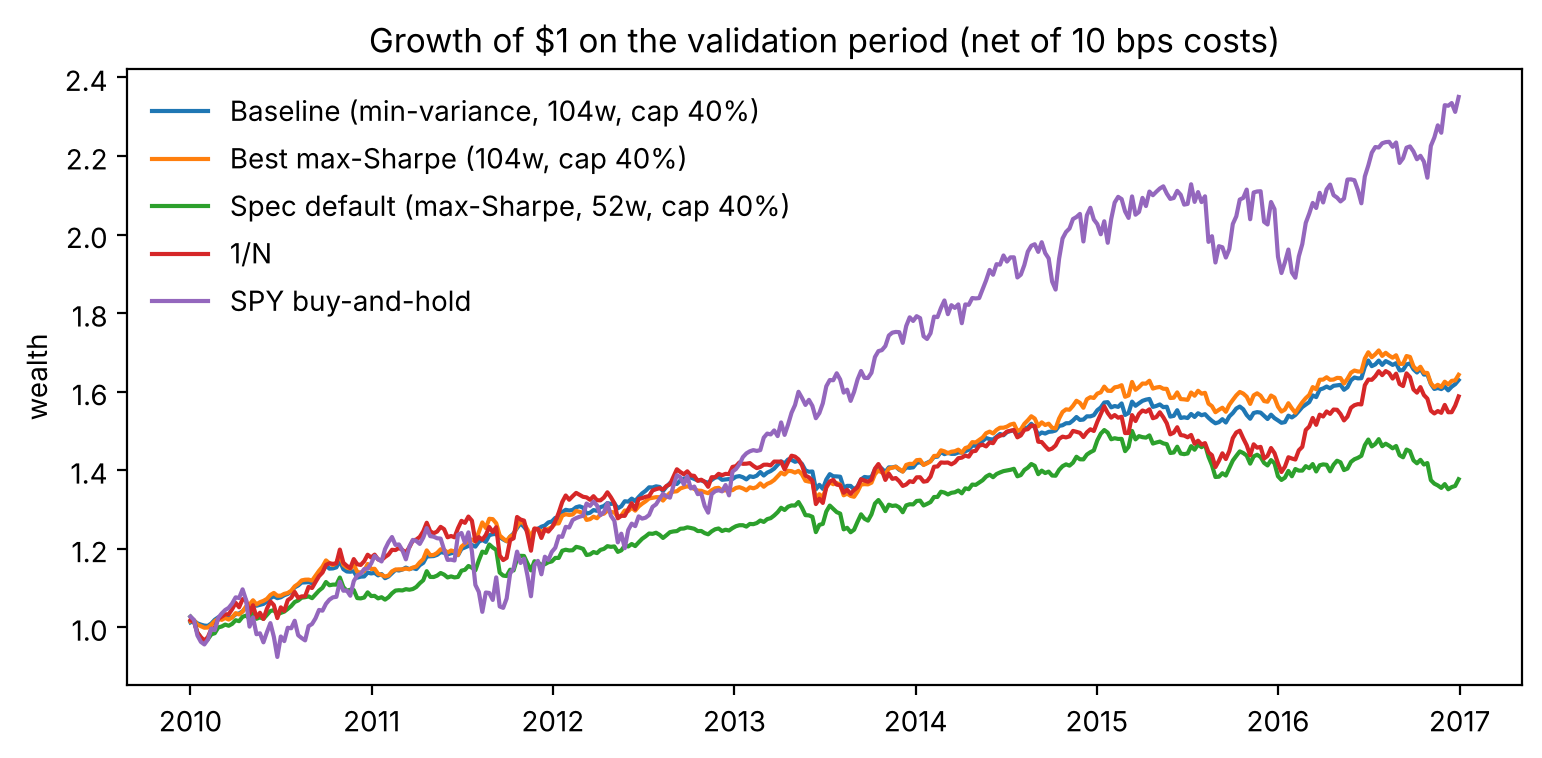

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
for name, r in results.items():
    ax.plot((1 + r["net"]).cumprod(), label=name)
ax.set_title("Growth of $1 on the validation period (net of 10 bps costs)")
ax.set_ylabel("wealth")
ax.legend(frameon=False)
plt.show()

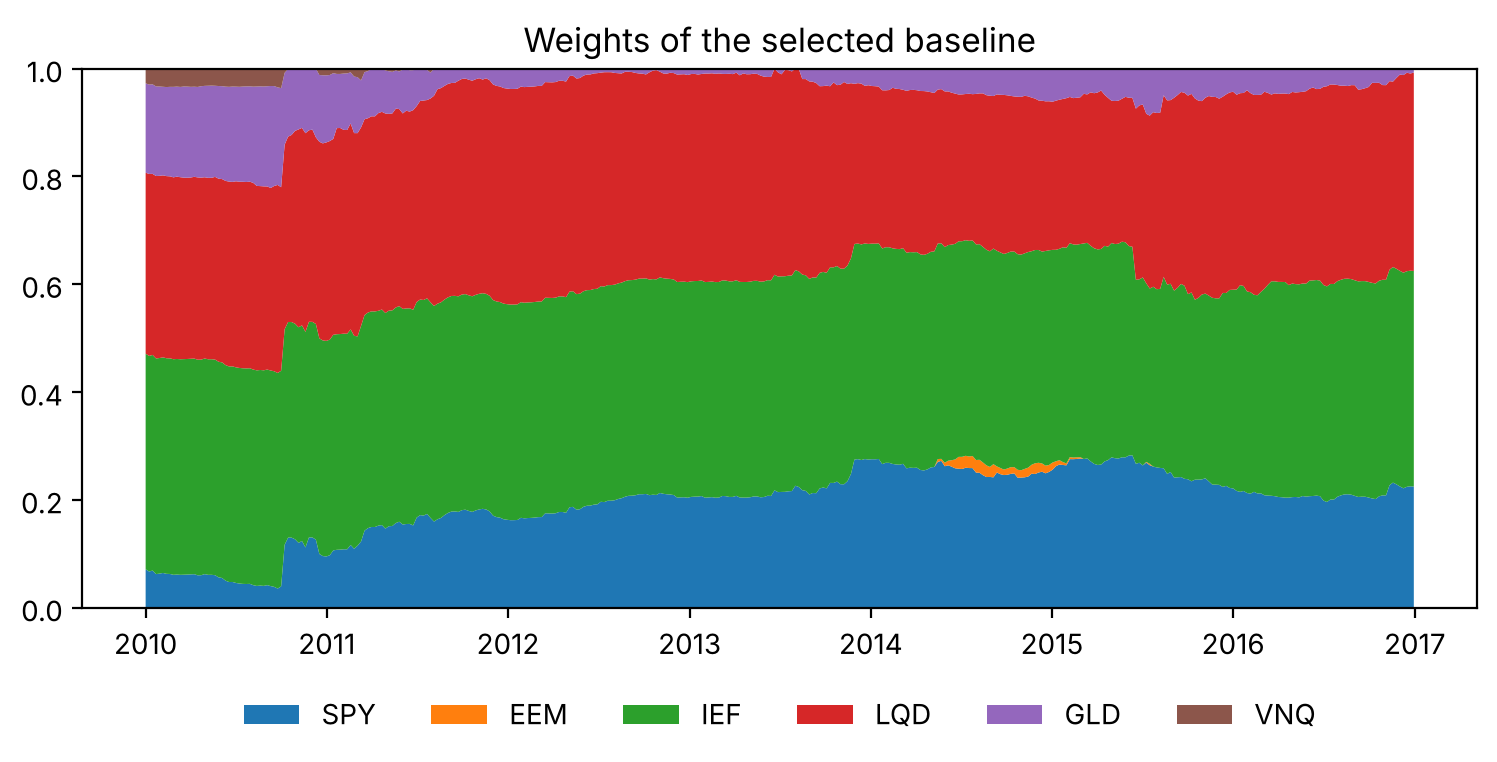

In [8]:
w = results[BEST_NAME][[f"w_{a}" for a in C.ASSETS]]
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.stackplot(w.index, w.T.values, labels=C.ASSETS)
ax.set_ylim(0, 1)
ax.set_title("Weights of the selected baseline")
ax.legend(ncol=6, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.show()

## 4. Forecast quality (ML level)

* **MSE** of $\hat\mu_t$ against the realized $r_{t+1}$, and **sign hit rate**.
* **Out-of-sample $R^2$** against the historical mean (expanding window since 2005), as in Campbell and Thompson (2008):
  $R^2 > 0$ means better than the plain average of everything observed so far (0 by construction for that average).
* **Variance forecast**: predicted vs realized variance of the minimum-variance portfolio built from $\hat\Sigma_t$.
  A ratio realized / predicted above 1 means the risk is underestimated.

In [9]:
mu_hist, var_hist = walk_forward_forecasts(df, expanding_mean_estimate, C.VALID_START, C.VALID_END)
fc = {"historical mean (benchmark)": forecast_metrics(mu_hist, var_hist, C.ASSETS, bench_mu=mu_hist)}
for window in [26, 52, 104]:
    mu_w, var_w = walk_forward_forecasts(df, rolling_estimate(window), C.VALID_START, C.VALID_END)
    fc[f"rolling {window}w"] = forecast_metrics(mu_w, var_w, C.ASSETS, bench_mu=mu_hist)
pd.DataFrame(fc).T

,mse_mu,hit_rate,r2_oos,var_mse,var_ratio
historical mean (benchmark),4.272e-04,0.570,0.000,9.514e-09,0.678
rolling 26w,4.444e-04,0.533,-0.040,1.064e-08,0.903
rolling 52w,4.342e-04,0.543,-0.016,8.297e-09,0.865
rolling 104w,4.293e-04,0.556,-0.005,8.021e-09,0.700


## 5. Notes for the report

Interpretation is written after reading the tables above (see `report/week2_notes.md`):
the selected configuration, how it compares with 1/N and SPY, turnover and costs, and the forecast metrics.
These numbers are on validation only; the test period stays untouched until week 4.